**Lab assignment 1**

Notebook #2 focused on how to **implement and test additional heuristics**, as well as on comparing heuristics.

This is the main notebook on which to develop and validate the additional heuristic functions requested for this lab assignment.

**Authors:** Borys Szycher, Marcin Otte

In [1]:
# %pip install matplotlib tabulate numpy 

> **IMPORTANT**: you may need to install several python packages depending on the computer you are working with. Lab computers should have all necessary packages installed.
> To install the packages, uncomment (removing the #) and run the line above.

In [2]:
import math
import search
from search import *

**Method implementing an additional heuristic**

In this case, the new heuristic is just multiplying by 2 the Manhattan distance.

In [3]:
# New heuristic to be tested: 2 * Manhattan distance
def new_heuristic(state, end_state):
    """
    Heuristic multiplying by 2 the Manhattan distance
    """
    return 2 * getManhattanDistance(state, end_state)

# A single instruction is enough for run_algorithm and 
# run_all_algorithms to register the new heuristic.
register_heuristic("New Heuristic", new_heuristic)

## Activities 1–5: new heuristics

All heuristics receive `(state, end_state)` as 1-D lists and compute the board size from the length of the state, so they work for any n×n puzzle (not only 3×3). The blank (0) is never counted as a tile.

**Activity 1 – MISPLACED TILES**, h(n) = W(n): number of tiles that are not in their goal position.

In [4]:
def misplaced_tiles(state, end_state):
    """Number of tiles (blank excluded) that are not in their goal position."""
    return sum(1 for x, y in zip(state, end_state) if x != y and x != 0)

register_heuristic("Misplaced", misplaced_tiles)

**Activity 2 – A\* Euclidean**: sum over the tiles of the straight-line distance between the current and the goal position.

In [5]:
def euclidian(state, end_state):
    """Sum of the Euclidean distances of every tile to its goal position."""
    size = int(math.sqrt(len(state)))
    total = 0.0
    for tile in range(1, len(state)):
        idx = state.index(tile)
        goal = end_state.index(tile)
        dx = idx // size - goal // size
        dy = idx % size - goal % size
        total += math.sqrt(dx ** 2 + dy ** 2)
    return int(total)

register_heuristic("A* Euclid", euclidian)

**Activity 3 – ROWS_COLUMNS**, h(n) = RowCol(n): +1 for every tile outside its goal row, +1 for every tile outside its goal column (0..2 per tile).

In [6]:
def rows_columns(state, end_state):
    """+1 if a tile is out of its goal row, +1 if it is out of its goal column."""
    size = int(math.sqrt(len(state)))
    total = 0
    for tile in range(1, len(state)):
        idx = state.index(tile)
        goal = end_state.index(tile)
        if idx // size != goal // size:
            total += 1
        if idx % size != goal % size:
            total += 1
    return total

register_heuristic("RowCol", rows_columns)

**Activity 4 – A\* Euclidean + LC**: Euclidean distance plus the linear-conflict penalty of `search.getLinear_conflict` (which already returns 2 per selected conflict).

In [7]:
def euclidian_plus_lc(state, end_state):
    return euclidian(state, end_state) + getLinear_conflict(state, end_state)

register_heuristic("A* Euclid + LC", euclidian_plus_lc)

**Activity 5 – Proposed heuristics**

* **Proposed (A\*)** – `combination(n) = max(Euclid(n), RowCol(n)) + LC(n)`. The maximum of two admissible heuristics is admissible and at least as informed as each of them; the LC penalty adds the extra moves needed to solve linear conflicts.
* **Proposed (1.5x)** – `combination_2(n) = 1.5 · combination(n)`. A *weighted A* (algorithm A)*: it deliberately gives up admissibility to expand far fewer nodes. Because `combination` is admissible, the cost of the solution found is guaranteed to be at most 1.5 × the optimal cost.

In [8]:
def combination(state, end_state):
    e = euclidian(state, end_state)
    rc = rows_columns(state, end_state)
    lc = getLinear_conflict(state, end_state)
    return max(e, rc) + lc

register_heuristic("Proposed (A*)", combination)


W = 1.5

def combination_2(state, end_state):
    return W * combination(state, end_state)

register_heuristic("Proposed (1.5x)", combination_2)

**Example with size 3**

We define the initial state and the goal state, we run all the algorithms available, and we display the results.

BFS executed


DFS-B executed


ID executed
Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
IDA* (Manhattan) executed
New Heuristic executed
Misplaced executed
A* Euclid executed
RowCol executed
A* Euclid + LC executed
Proposed (A*) executed
Proposed (1.5x) executed
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |    Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+=============+===================+==================+====================+
| BFS               |     22 |      23 | 0.399636    |            233687 |            86871 |             110729 |
+-------------------+--------+---------+-------------+-------------------+------------------+--------------------+
| DFS-B             |     38 |      40 | 1.87827     |           2028383 |          1301341 |                 41 |
+-------------------+--------+---------+-----------

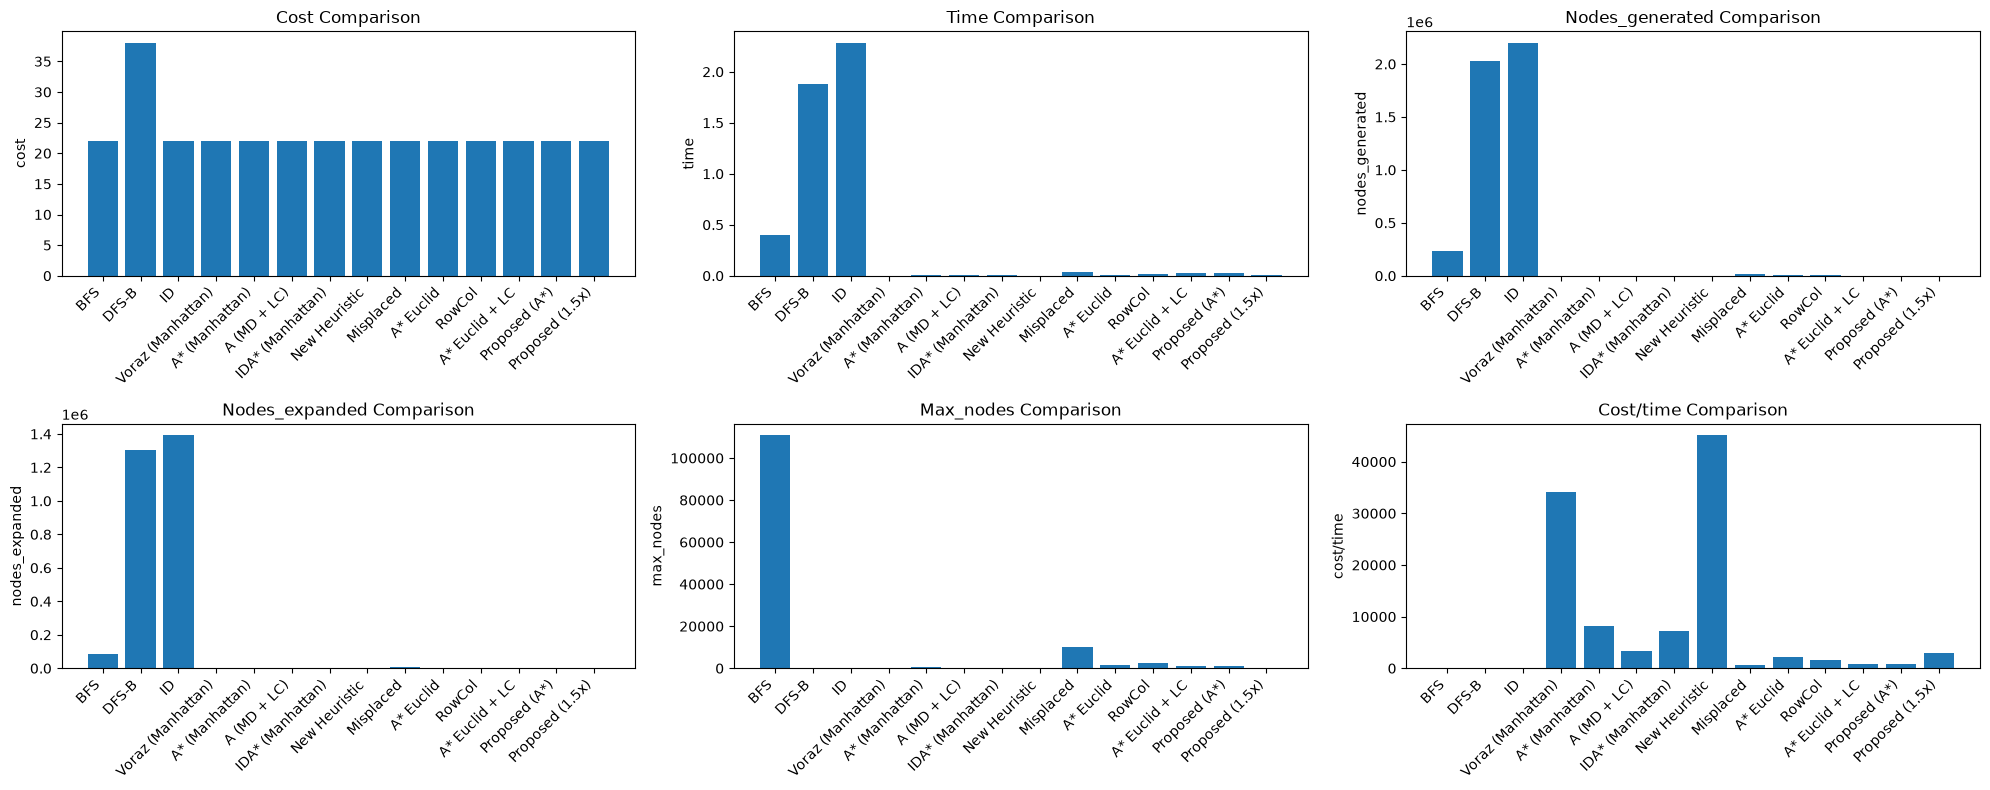

In [9]:
# Size 3

size = 3  # Example for a 3x3 puzzle

initial_state_matrix = [
    [7, 8, 1],
    [4, 0, 6],
    [2, 3, 5]
]


end_state_matrix = [
    [1, 2, 3],
    [8, 0, 4],
    [7, 6, 5]
]

# Convert the matrix into a one-dimensional list
initial_state = [num for row in initial_state_matrix for num in row]
# Convert the matrix into a one-dimensional list
end_state = [num for row in end_state_matrix for num in row]

# Run all of the algorithms and show the results as a table
results = {}
if isSolvable(initial_state, end_state):
    # Calling the function that runs all the algorithms
    results = run_all_algorithms(initial_state, end_state, size, 40)
    show_results(results)
    plot_algorithm_comparison(results)
else:
    print("The puzzle is not solvable.")




## Activity 6 – tools for the admissibility / consistency study

* `get_optimal_cost` obtains h\*(n) by running **A (MD + LC)** (admissible ⇒ optimal; on the example above it gives the same cost as BFS, 22, but it is much faster).
* `study_heuristic` checks, over several initial states, that h(goal) = 0, h ≥ 0 and h(n) ≤ h\*(n), and runs `check_consistency` (exploring **all** reachable states, `max_states=None`) from several different initial states.
* `check_consistency_tol` is the same test as `search.check_consistency` but with a tolerance of 1e-9. It is needed for heuristics with real values: with floating-point arithmetic `12.4787… − 11.4787…` can give `1.0000000000000018 > 1`, which is a rounding error, not a real violation. (Our final `euclidian` returns `int(total)`, so its values are integers and the plain check is enough; the tolerant check is only applied when a counterexample appears.)

In [10]:
import io, contextlib, random
from tabulate import tabulate

def get_optimal_cost(initial_state, end_state, size):
    with contextlib.redirect_stdout(io.StringIO()):
        return run_algorithm('A (MD + LC)', initial_state, end_state, size)['A (MD + LC)']['cost']


def check_consistency_tol(heuristic, initial_state, end_state, size, max_states=None, eps=1e-9):
    """Same as search.check_consistency, but h(n) <= 1 + h(n') + eps (tolerates float rounding)."""
    pending = [tuple(initial_state)]
    visited = set()
    k = 0
    while k < len(pending):
        if max_states is not None and len(visited) >= max_states:
            return {'consistent': None, 'complete': False, 'states_checked': len(visited), 'counterexample': None}
        state = pending[k]
        k += 1
        if state in visited:
            continue
        visited.add(state)
        state_h = heuristic(list(state), end_state)
        for child in getChildren(list(state), size):
            child_h = heuristic(child, end_state)
            if state_h > 1 + child_h + eps:
                return {'consistent': False, 'complete': False, 'states_checked': len(visited),
                        'counterexample': {'state': list(state), 'child': child, 'h_state': state_h,
                                           'h_child': child_h, 'step_cost': 1}}
            if tuple(child) not in visited:
                pending.append(tuple(child))
    return {'consistent': True, 'complete': True, 'states_checked': len(visited), 'counterexample': None}


def study_heuristic(heuristic, name, test_states, end_state, size, consistency_starts=3, tolerance=False):
    print(f"Heuristic: {name}")
    print("-" * 70)
    print("h(goal) =", heuristic(end_state, end_state))
    rows = []
    for s in test_states:
        h = heuristic(s, end_state)
        opt = get_optimal_cost(s, end_state, size)
        rows.append([s, round(h, 3), opt, h >= 0, h <= opt])
    print(tabulate(rows, headers=["Initial state", "h(n)", "h*(n)", "h >= 0", "h <= h*"], tablefmt="simple"))
    over = sum(1 for r in rows if not r[4])
    print(f"Overestimations: {over}/{len(rows)} states;  max h/h* = {max(r[1] / r[2] for r in rows):.3f}")
    print()
    for s in test_states[:consistency_starts]:
        res = check_consistency(heuristic, s, end_state, size, max_states=None)
        print(f"check_consistency from {s}:")
        print("   ", res)
        if tolerance and res['consistent'] is False:
            c = res['counterexample']
            print(f"    violation h(n) - h(n') = {c['h_state'] - c['h_child']!r}")
            print("    with tolerance 1e-9:", check_consistency_tol(heuristic, s, end_state, size))


# Test set: the example of the bulletin + 5 random solvable states (fixed seed -> reproducible)
size = 3
random.seed(42)
test_states = [initial_state] + [generate_random_state(size, end_state) for _ in range(5)]
for s in test_states:
    print(s, "h* =", get_optimal_cost(s, end_state, size))

[7, 8, 1, 4, 0, 6, 2, 3, 5] h* = 22
[3, 6, 7, 4, 8, 2, 5, 0, 1] h* = 29
[7, 2, 5, 6, 0, 3, 4, 1, 8] h* = 24
[3, 0, 1, 7, 8, 5, 4, 2, 6] h* = 21
[4, 2, 1, 7, 8, 6, 0, 5, 3] h* = 18
[5, 0, 1, 8, 7, 4, 3, 6, 2] h* = 23


**Admissibility and consistency study example**

Using the initial state defined above, we compare the heuristic value against the optimal cost, provided by BFS. Then, `check_consistency` is used to find a possible consistency counterexample. These tests, performed over a single example (a single initial state) provide some evidence, although their results do not compose a general justification.

In [11]:
# Admissibility study for the previous initial state
h_initial = new_heuristic(initial_state, end_state)
h_goal = new_heuristic(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    new_heuristic, initial_state, end_state, size, max_states=10000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 32
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? False
Consistency test results:
{'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [7, 8, 1, 4, 0, 6, 2, 3, 5], 'child': [7, 0, 1, 4, 8, 6, 2, 3, 5], 'h_state': 32, 'h_child': 30, 'step_cost': 1}}


**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:**

With the initial state of the bulletin, `2*Manhattan` gives **h = 32**, while the optimal cost (BFS) is **22**: the heuristic **overestimates** the real cost, so it is **not admissible**. It is not consistent either: `check_consistency` finds a counterexample in the very first state, h(n) = 32 > 1 + h(n') = 1 + 30.

Therefore the search with this heuristic is **not an A\* search** but an **A-type search** (f = g + h with a non-admissible h). In this example it happened to find the optimal cost (22) expanding only 48 nodes (A (MD + LC) needed 158), but this is luck: nothing guarantees optimality. We can be sure it is not A\*, because one single counterexample (32 > 22) is enough to prove that the heuristic is not admissible.

### Study of **Misplaced** (`misplaced_tiles`)

In [12]:
# Admissibility study for the previous initial state
h_initial = misplaced_tiles(initial_state, end_state)
h_goal = misplaced_tiles(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    misplaced_tiles, initial_state, end_state, size, max_states=200000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 7
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True


Consistency test results:
{'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


In [13]:
study_heuristic(misplaced_tiles, "Misplaced", test_states, end_state, size)

Heuristic: Misplaced
----------------------------------------------------------------------
h(goal) = 0
Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]       7       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]       8       29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]       7       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]       8       21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]       7       18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]       5       23  True      True
Overestimations: 0/6 states;  max h/h* = 0.389



check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [7, 2, 5, 6, 0, 3, 4, 1, 8]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **Misplaced is admissible and consistent → the search is A\*.**

* *Admissibility*: h(goal) = 0, h ≥ 0 and h ≤ h\* in **6/6** test states (max h/h\* = 0.389, e.g. 7 vs 22 for the bulletin state). Theoretical argument: every misplaced tile needs at least one move, and one move only moves one tile, so W(n) ≤ h\*(n).
* *Consistency*: `check_consistency` with `max_states=None` returns `consistent: True, complete: True, states_checked: 181440` from 3 different initial states. 181440 = 9!/2 is the whole reachable state space of the 3×3 puzzle, so for this goal the check is exhaustive, not only a sample. Theoretical argument (valid for any size): a move changes the position of exactly one tile, so W changes by at most 1 = step cost.
* *Behaviour*: it is the least informed heuristic (it only says *whether* a tile is misplaced, not *how far*): 6452 expanded nodes in the example and 9435 on average in the benchmark below, versus 158 / 263.6 for A (MD + LC). It always finds the optimal solution (22).

### Study of **A* Euclid** (`euclidian`)

In [14]:
# Admissibility study for the previous initial state
h_initial = euclidian(initial_state, end_state)
h_goal = euclidian(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    euclidian, initial_state, end_state, size, max_states=10000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 13
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True
Consistency test results:
{'consistent': None, 'complete': False, 'states_checked': 10000, 'counterexample': None}


In [15]:
study_heuristic(euclidian, "A* Euclid", test_states, end_state, size, tolerance=True)

Heuristic: A* Euclid
----------------------------------------------------------------------
h(goal) = 0


Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]      13       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]      16       29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]      13       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]      12       21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]      10       18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]      11       23  True      True
Overestimations: 0/6 states;  max h/h* = 0.591



check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [7, 2, 5, 6, 0, 3, 4, 1, 8]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **Euclid (rounded down, `int(total)`) is admissible and consistent → the search is A\*.**

Our implementation returns the integer part of the sum of the Euclidean distances, ⌊E(n)⌋.

* *Admissibility*: h(goal) = 0, h ≥ 0 and h ≤ h\* in **6/6** test states (max h/h\* = 0.591, e.g. 13 vs 22). Theory: the straight-line distance of a tile is never larger than its Manhattan distance (√(dx²+dy²) ≤ |dx|+|dy|), so ⌊E⌋ ≤ E ≤ MD ≤ h\*.
* *Consistency*: `check_consistency` returns `consistent: True, complete: True, states_checked: 181440` from 3 different initial states (whole 3×3 space). Theory: a move displaces one tile by a distance of 1, so by the triangle inequality E changes by at most 1, and then ⌊E⌋ also changes by at most 1. (The single-state test above, limited to `max_states=10000`, returns `None`: no counterexample, but incomplete.) Rounding down also removes the floating-point problem: with the real-valued version, `check_consistency` reported false "violations" of h(n) − h(n') = 1.0000000000000018, which were rounding errors. `check_consistency_tol` was written for that case.
* *Behaviour*: optimal cost (22), but less informed than Manhattan (1057 expanded nodes vs 266 for A\* Manhattan), because ⌊E⌋ ≤ MD for every state.

### Study of **RowCol** (`rows_columns`)

In [16]:
# Admissibility study for the previous initial state
h_initial = rows_columns(initial_state, end_state)
h_goal = rows_columns(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    rows_columns, initial_state, end_state, size, max_states=200000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 11
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True


Consistency test results:
{'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


In [17]:
study_heuristic(rows_columns, "RowCol", test_states, end_state, size)

Heuristic: RowCol
----------------------------------------------------------------------
h(goal) = 0
Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]      11       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]      11       29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]      11       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]       9       21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]       9       18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]       9       23  True      True
Overestimations: 0/6 states;  max h/h* = 0.500



check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


check_consistency from [7, 2, 5, 6, 0, 3, 4, 1, 8]:
    {'consistent': True, 'complete': True, 'states_checked': 181440, 'counterexample': None}


**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **RowCol is admissible and consistent → the search is A\*.**

* *Admissibility*: h(goal) = 0, h ≥ 0 and h ≤ h\* in **6/6** test states (max h/h\* = 0.5, e.g. 11 vs 22). Theory: a tile outside its goal row needs at least one vertical move and a tile outside its goal column at least one horizontal move, so per tile RowCol = min(|dx|,1) + min(|dy|,1) ≤ |dx| + |dy|, i.e. RowCol ≤ MD ≤ h\*.
* *Consistency*: `check_consistency` returns `consistent: True, complete: True, states_checked: 181440` (the whole 3×3 space) from 3 different initial states. Theory: a move changes either the row or the column of one single tile, so h changes by at most 1.
* *Behaviour*: optimal (22) but weakly informed: 1601 expanded nodes in the example (2355 on average in the benchmark), better only than Misplaced.

### Study of **A* Euclid + LC** (`euclidian_plus_lc`)

In [18]:
# Admissibility study for the previous initial state
h_initial = euclidian_plus_lc(initial_state, end_state)
h_goal = euclidian_plus_lc(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    euclidian_plus_lc, initial_state, end_state, size, max_states=10000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 13
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True
Consistency test results:
{'consistent': False, 'complete': False, 'states_checked': 7, 'counterexample': {'state': [0, 7, 1, 4, 8, 6, 2, 3, 5], 'child': [4, 7, 1, 0, 8, 6, 2, 3, 5], 'h_state': 15, 'h_child': 13, 'step_cost': 1}}


In [19]:
study_heuristic(euclidian_plus_lc, "A* Euclid + LC", test_states, end_state, size)

Heuristic: A* Euclid + LC
----------------------------------------------------------------------
h(goal) = 0
Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]      13       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]      18       29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]      15       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]      14       21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]      12       18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]      11       23  True      True
Overestimations: 0/6 states;  max h/h* = 0.667

check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': False, 'complete': False, 'states_checked': 7, 'counterexample': {'state': [0, 7, 1, 4, 8, 6, 2, 3, 5], 'child': [4, 7, 1, 0, 8, 6, 2, 3, 5], 'h_state': 15, 'h_child': 13, 'step_cost': 1}}
check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': False, 'complete

**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **Euclid + LC is admissible but NOT consistent. The search is still A\*.**

* *Admissibility*: h(goal) = 0, h ≥ 0 and h ≤ h\* in **6/6** test states (max h/h\* = 0.667). Theory: ⌊E⌋ ≤ MD, so ⌊E⌋ + LC ≤ MD + LC ≤ h\* (MD + LC is admissible).
* *Consistency*: counterexamples from all 3 initial states, e.g. state `[0, 7, 1, 4, 8, 6, 2, 3, 5]` with h = 15 and child `[4, 7, 1, 0, 8, 6, 2, 3, 5]` with h = 13: h drops by **2 > 1**. The other starts give 18 → 16 and 15 → 13. Reason: a move that takes a tile out of its row/column can remove a linear conflict (LC −2), while its Euclidean distance grows by less than 1 (e.g. from 1 to √2 = 1.41 when the tile becomes diagonal to its goal). Manhattan would grow by exactly 1, which is why MD + LC is consistent and Euclid + LC is not.
* *Is it A\*?* Yes: admissibility is enough for optimality, and `graphSearch` re-opens closed nodes when a cheaper path is found. Without consistency, though, some nodes may be expanded more than once. Cost 22 (optimal), 666 expanded nodes, better than Euclid alone (1057) thanks to LC.

### Study of **Proposed (A*)** (`combination`)

In [20]:
# Admissibility study for the previous initial state
h_initial = combination(initial_state, end_state)
h_goal = combination(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    combination, initial_state, end_state, size, max_states=10000
)
print("Consistency test results:")
print(consistency_result)


H value in the initial state: 13
H value in the goal state: 0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True
Consistency test results:
{'consistent': False, 'complete': False, 'states_checked': 7, 'counterexample': {'state': [0, 7, 1, 4, 8, 6, 2, 3, 5], 'child': [4, 7, 1, 0, 8, 6, 2, 3, 5], 'h_state': 15, 'h_child': 13, 'step_cost': 1}}


In [21]:
study_heuristic(combination, "Proposed (A*)", test_states, end_state, size)

Heuristic: Proposed (A*)
----------------------------------------------------------------------
h(goal) = 0


Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]      13       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]      18       29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]      15       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]      14       21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]      12       18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]      11       23  True      True
Overestimations: 0/6 states;  max h/h* = 0.667

check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': False, 'complete': False, 'states_checked': 7, 'counterexample': {'state': [0, 7, 1, 4, 8, 6, 2, 3, 5], 'child': [4, 7, 1, 0, 8, 6, 2, 3, 5], 'h_state': 15, 'h_child': 13, 'step_cost': 1}}
check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [3, 6, 7, 4, 8, 2, 5, 0, 1], 'child': [3, 6, 7, 4,

**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **Proposed (A\*) = max(Euclid, RowCol) + LC is admissible but NOT consistent → A\* search.**

* *Admissibility*: h(goal) = 0, h ≥ 0 and h ≤ h\* in **6/6** test states (max h/h\* = 0.667). Theory: ⌊E⌋ ≤ MD and RowCol ≤ MD, so max(⌊E⌋, RowCol) + LC ≤ MD + LC ≤ h\*.
* *Consistency*: the same counterexamples as Euclid + LC (15 → 13, 18 → 16, 15 → 13), caused by the same Euclid/LC interaction.
* *Behaviour*: optimal (22) and the best of our admissible heuristics (607 expanded in the example; 848 on average in the benchmark vs 915.5 for Euclid + LC). However, it can never be more informed than A (MD + LC), because it is always ≤ MD + LC. This is why we also propose the weighted version below.

### Study of **Proposed (1.5x)** (`combination_2`)

In [22]:
# Admissibility study for the previous initial state
h_initial = combination_2(initial_state, end_state)
h_goal = combination_2(end_state, end_state)
optimal_cost = results['BFS']['cost'] # requires that BFS has been run and is in the results

print("H value in the initial state:", h_initial)
print("H value in the goal state:", h_goal)
print("BFS optimal cost:", optimal_cost)
print("¿Is H non-negative in this example?", h_initial >= 0)
print("¿Does H equal to 0 in the goal state?", h_goal == 0)
print("¿Does H never exceed the optimal cost?", h_initial <= optimal_cost)

# Consistency study from the previous initial state
consistency_result = check_consistency(
    combination_2, initial_state, end_state, size, max_states=10000
)
print("Consistency test results:")
print(consistency_result)

H value in the initial state: 19.5
H value in the goal state: 0.0
BFS optimal cost: 22
¿Is H non-negative in this example? True
¿Does H equal to 0 in the goal state? True
¿Does H never exceed the optimal cost? True
Consistency test results:
{'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [7, 8, 1, 4, 0, 6, 2, 3, 5], 'child': [7, 8, 1, 4, 3, 6, 2, 0, 5], 'h_state': 19.5, 'h_child': 18.0, 'step_cost': 1}}


In [23]:
study_heuristic(combination_2, "Proposed (1.5x)", test_states, end_state, size)

Heuristic: Proposed (1.5x)
----------------------------------------------------------------------
h(goal) = 0.0


Initial state                  h(n)    h*(n)  h >= 0    h <= h*
---------------------------  ------  -------  --------  ---------
[7, 8, 1, 4, 0, 6, 2, 3, 5]    19.5       22  True      True
[3, 6, 7, 4, 8, 2, 5, 0, 1]    27         29  True      True
[7, 2, 5, 6, 0, 3, 4, 1, 8]    22.5       24  True      True
[3, 0, 1, 7, 8, 5, 4, 2, 6]    21         21  True      True
[4, 2, 1, 7, 8, 6, 0, 5, 3]    18         18  True      True
[5, 0, 1, 8, 7, 4, 3, 6, 2]    16.5       23  True      True
Overestimations: 0/6 states;  max h/h* = 1.000

check_consistency from [7, 8, 1, 4, 0, 6, 2, 3, 5]:
    {'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [7, 8, 1, 4, 0, 6, 2, 3, 5], 'child': [7, 8, 1, 4, 3, 6, 2, 0, 5], 'h_state': 19.5, 'h_child': 18.0, 'step_cost': 1}}
check_consistency from [3, 6, 7, 4, 8, 2, 5, 0, 1]:
    {'consistent': False, 'complete': False, 'states_checked': 1, 'counterexample': {'state': [3, 6, 7, 4, 8, 2, 5, 0, 1], 'child': [3, 6, 7

In [24]:
# The 6 test states are not enough to expose the overestimation of Proposed (1.5x):
# search for counterexamples h(n) > h*(n) over 200 random states.
random.seed(1)
overestimations = []
for _ in range(200):
    s = generate_random_state(size, end_state)
    h = combination_2(s, end_state)
    opt = get_optimal_cost(s, end_state, size)
    if h > opt:
        overestimations.append((s, h, opt))
print(f"h(n) > h*(n) in {len(overestimations)}/200 random states")
for s, h, opt in overestimations[:5]:
    print(f"  {s}: h = {h}, h* = {opt}")

h(n) > h*(n) in 35/200 random states
  [3, 6, 4, 0, 2, 5, 7, 1, 8]: h = 19.5, h* = 19
  [3, 6, 5, 7, 2, 0, 1, 4, 8]: h = 25.5, h* = 25
  [6, 7, 8, 4, 3, 1, 5, 0, 2]: h = 24.0, h* = 23
  [2, 3, 5, 1, 7, 4, 8, 6, 0]: h = 13.5, h* = 12
  [7, 6, 8, 5, 0, 2, 1, 3, 4]: h = 25.5, h* = 22


**Question**

How does the new heuristic behave?  Is the search with this heuristic an A* search?  Can you be sure about that?

**Reply:** **Proposed (1.5x) is NOT admissible and NOT consistent → it is an A-type search (weighted A\*), not A\*.**

* *Admissibility*: h(goal) = 0 and h ≥ 0. In the 6 test states it never exceeds h\*, although it reaches it exactly twice (21 = 21, 18 = 18, max h/h\* = 1.000). The extra test over 200 random states finds **35/200 overestimations**, e.g. `[7, 6, 8, 5, 0, 2, 1, 3, 4]` with h = 25.5 > h\* = 22 and `[2, 3, 5, 1, 7, 4, 8, 6, 0]` with h = 13.5 > 12. This shows why several examples are needed: a handful of states may not reveal non-admissibility.
* *Consistency*: counterexample already in the first state: 19.5 → 18.0 (drop of 1.5 > 1).
* *Guarantee*: since `combination` is admissible, f = g + 1.5·h is a weighted A\*, and the cost of the solution is at most **1.5 × optimal**. In the benchmark below it is optimal in 28/30 cases, at most 2 moves longer.
* *Behaviour*: on the bulletin example it finds cost 22 with 174 expanded nodes, slightly more than A (MD + LC) (158). On the 4×4 example it is the fastest search (see below).

## Activity 6 – comparison over many random instances

A single initial state can be misleading, so all the heuristic searches are run over 30 random solvable 3×3 states (fixed seed, same goal as above). `opt.` counts how many times the solution has the optimal cost (given by A (MD + LC)).

In [25]:
import statistics

bench_names = ['Voraz (Manhattan)', 'A* (Manhattan)', 'A (MD + LC)', 'IDA* (Manhattan)',
               'Misplaced', 'A* Euclid', 'RowCol', 'A* Euclid + LC', 'Proposed (A*)', 'Proposed (1.5x)']
N_BENCH = 30
random.seed(2026)
bench_states = [generate_random_state(size, end_state) for _ in range(N_BENCH)]

bench = {n: {k: [] for k in ['cost', 'gen', 'exp', 'mem', 'time', 'extra']} for n in bench_names}
for s in bench_states:
    with contextlib.redirect_stdout(io.StringIO()):
        opt = run_algorithm('A (MD + LC)', s, end_state, size)['A (MD + LC)']['cost']
        for n in bench_names:
            r = run_algorithm(n, s, end_state, size)[n]
            b = bench[n]
            b['cost'].append(r['cost']); b['gen'].append(r['nodes_generated'])
            b['exp'].append(r['nodes_expanded']); b['mem'].append(r['max_nodes'])
            b['time'].append(r['time']); b['extra'].append(r['cost'] - opt)

rows = []
for n in bench_names:
    b = bench[n]
    rows.append([n, statistics.mean(b['cost']), statistics.mean(b['gen']), statistics.mean(b['exp']),
                 statistics.mean(b['mem']), statistics.mean(b['time']),
                 f"{sum(1 for e in b['extra'] if e == 0)}/{N_BENCH}", max(b['extra'])])
print(tabulate(rows, headers=["Algorithm", "Mean cost", "Mean generated", "Mean expanded",
                              "Mean max stored", "Mean time (s)", "opt.", "Max extra cost"],
               floatfmt=".4g", tablefmt="grid"))

+-------------------+-------------+------------------+-----------------+-------------------+-----------------+--------+------------------+
| Algorithm         |   Mean cost |   Mean generated |   Mean expanded |   Mean max stored |   Mean time (s) | opt.   |   Max extra cost |
+===================+=============+==================+=================+===================+=================+========+==================+
| Voraz (Manhattan) |       49.67 |      687.9       |           256.2 |       419.2       |        0.002231 | 2/30   |               54 |
+-------------------+-------------+------------------+-----------------+-------------------+-----------------+--------+------------------+
| A* (Manhattan)    |       21.87 |     1435         |           532.6 |       860.3       |        0.004717 | 30/30  |                0 |
+-------------------+-------------+------------------+-----------------+-------------------+-----------------+--------+------------------+
| A (MD + LC)       |      

**Analysis:**

* **Optimality**: all admissible heuristics (A\* Manhattan, MD + LC, IDA\*, Misplaced, Euclid, RowCol, Euclid + LC, Proposed (A\*)) are optimal in **30/30** instances, as admissibility predicts. Greedy is optimal in only 2/30 (mean cost 49.67 vs 21.87, up to 54 extra moves). Proposed (1.5x) is optimal in 28/30, at most 2 extra moves.
* **Informedness (mean expanded nodes)**: A (MD + LC) 263.6 < Proposed (1.5x) 364.8 < A\* Manhattan 532.6 < Proposed (A\*) 848 < Euclid + LC 915.5 < Euclid 1564 < RowCol 2355 < Misplaced 9435. The order follows the dominance relations: Misplaced ≤ RowCol ≤ MD and ⌊E⌋ ≤ MD, and adding LC always helps.
* **Memory**: IDA\* stores only ~23 nodes (the current path) but generates more nodes (2695) than A\* Manhattan. The A\* searches store hundreds to thousands of nodes (Misplaced: 14310).
* **Time**: a better heuristic is more expensive per node (LC is costly). So A\* Manhattan (~0.005 s) is faster than A (MD + LC) (~0.011 s) on 3×3, even though it expands twice as many nodes.

**Choice of the two best heuristics for Activity 7** (only our own heuristics are candidates, not the template's Manhattan / MD + LC):
* **A\* Euclid + LC**: the best heuristic of Activities 1–4. It is admissible (30/30 optimal) with 915.5 mean expanded nodes, against 1564 for Euclid, 2355 for RowCol and 9435 for Misplaced. Proposed (A\*) (848) is almost the same heuristic, so comparing it with Euclid + LC would be redundant.
* **Proposed (1.5x)**: the best of all our heuristics (364.8 mean expanded nodes, 2.5× fewer than Euclid + LC), at the price of losing the optimality guarantee (28/30 optimal, at most +2 moves).

**Now try with size 4**

In [26]:
# Size 4

size = 4
initial_state_matrix = [
    [13, 2, 10, 3],
    [1, 12, 8, 4],
    [5, 0, 9, 6],
    [15, 14, 11, 7]
]

end_state_matrix = [
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 0]
]

# Convert the matrix into a one-dimensional list
initial_state = [num for row in initial_state_matrix for num in row]
# Convert the matrix into a one-dimensional list
end_state = [num for row in end_state_matrix for num in row]

# Uninformed searches (BFS, ID, DFS-B) are not run: the 4x4 space has 16!/2 ~ 1e13 states.
# Misplaced and RowCol are not run either: with them A* did not finish within 90 s
# (millions of nodes), they are far too poorly informed for this instance.
algorithms_4 = ['Voraz (Manhattan)', 'A* (Manhattan)', 'A (MD + LC)', 'A* Euclid',
                'A* Euclid + LC', 'Proposed (A*)', 'Proposed (1.5x)']

results = {}
if isSolvable(initial_state, end_state):
    for alg in algorithms_4:
        results.update(run_algorithm(alg, initial_state, end_state, size))
    show_results(results)
else:
    print("The puzzle is not solvable.")

Voraz (Manhattan) executed


A* (Manhattan) executed


A (MD + LC) executed


A* Euclid executed


A* Euclid + LC executed


Proposed (A*) executed


Proposed (1.5x) executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| Voraz (Manhattan) |    111 |     127 |  0.0304928 |              4983 |             1594 |               3277 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A* (Manhattan)    |     41 |      41 |  4.47415   |            645273 |           215568 |             403054 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A (MD + LC)       |     41 |      41 |  1.64665   |             68477 |            23099 |              43610 |
+-------------------+--------+---------+------------+----------

**Question**

What do you think now?

**Answer:**

The 4×4 puzzle has 16!/2 ≈ 1.05·10¹³ reachable states, so uninformed searches (BFS, ID, DFS-B) are not even attempted, and the quality of the heuristic becomes decisive (the optimal cost here is 41):

* A\* Euclid: 2,335,084 expanded nodes (~62 s); Euclid + LC: 454,045 (~34 s); Proposed (A\*): 422,052 (~40 s); A\* Manhattan: 215,568 (~4.5 s); A (MD + LC): **23,099 (~1.6 s)**. Misplaced and RowCol did not finish within 90 s.
* Proposed (1.5x) needed only **9,202 expanded nodes (~0.8 s)** and still found the optimal cost 41: weighting the heuristic pays off on this instance (2.5× fewer nodes than MD + LC).
* Greedy is extremely fast (1594 nodes, 0.03 s), but its solution costs 111 moves, almost 3× the optimum.

Conclusion: the differences that were milliseconds on 3×3 become orders of magnitude on 4×4. Small differences in informedness (Euclid vs Manhattan, with or without LC) translate into 10–100× more nodes and memory. Activity 7 checks on many instances whether the advantage of Proposed (1.5x) over A\* Euclid + LC (49× fewer nodes here: 9,202 vs 454,045) holds.

**Example with size 5**

In [27]:
# Size 5

size = 5
initial_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [0, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 24, 23, 11]
]

end_state_matrix = [
  [1, 2, 3, 4, 5],
  [6, 7, 8, 9, 10],
  [11, 12, 13, 14, 15],
  [16, 17, 18, 19, 20],
  [21, 22, 23, 24, 0]
]

# Convert the matrix into a one-dimensional list
initial_state = [num for row in initial_state_matrix for num in row]
# Convert the matrix into a one-dimensional list
end_state = [num for row in end_state_matrix for num in row]

# Misplaced is not run (did not finish within 90 s).
algorithms_5 = ['Voraz (Manhattan)', 'A* (Manhattan)', 'A (MD + LC)', 'A* Euclid', 'RowCol',
                'A* Euclid + LC', 'Proposed (A*)', 'Proposed (1.5x)']

results = {}
if isSolvable(initial_state, end_state):
    for alg in algorithms_5:
        results.update(run_algorithm(alg, initial_state, end_state, size))
    show_results(results)
else:
    print("The puzzle is not solvable.")

Voraz (Manhattan) executed


A* (Manhattan) executed


A (MD + LC) executed


A* Euclid executed


RowCol executed


A* Euclid + LC executed


Proposed (A*) executed


Proposed (1.5x) executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| Voraz (Manhattan) |    138 |     138 |   0.056829 |              5718 |             1688 |               3985 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A* (Manhattan)    |     30 |      30 |   1.92689  |            182180 |            55355 |             121598 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A (MD + LC)       |     30 |      30 |   3.56822  |            101039 |            30906 |              67518 |
+-------------------+--------+---------+------------+----------

**Answer:**

This 5×5 instance is close to the goal (only tiles 11, 23 and 24 are out of place), but tile 11 has to travel a long way. The optimal cost is 30; every admissible heuristic finds it, and Proposed (1.5x) also gives 30.

* Expanded nodes: A (MD + LC) **30,906** < Proposed (1.5x) 36,022 < A\* Manhattan 55,355 < Proposed (A\*) 141,523 < Euclid + LC 146,472 < Euclid 258,654 < RowCol 614,794. Misplaced did not finish within 90 s.
* Time: A\* Manhattan is the fastest (~1.9 s) despite expanding more nodes than MD + LC (~3.6 s) and Proposed (1.5x) (~5.4 s), because computing LC (and Euclid + RowCol) on a 5×5 board is much more expensive per node.
* Greedy: 0.06 s but cost 138.

The ranking by informedness is the same as on 3×3. Here the weighted proposal does **not** beat MD + LC (unlike the 4×4 example), so its advantage depends on the instance. The cost of evaluating the heuristic grows with the board size, so the fewest nodes does not always mean the lowest time.

**Now try size n, auto-generating initial and goal states**

Here we consider how to generalize to n the size of the puzzle.

Initial state:

 2  3  1
    8  7
 6  5  4

End state:

 1  2  3
 4  5  6
 7  8   

Voraz (Manhattan) executed
A* (Manhattan) executed
A (MD + LC) executed
Misplaced executed
A* Euclid executed
RowCol executed
A* Euclid + LC executed
Proposed (A*) executed


Proposed (1.5x) executed
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| Algorithm         |   Cost |   Depth |   Time (s) |   Nodes Generated |   Nodes Expanded |   Max Nodes Stored |
+===================+========+=========+============+===================+==================+====================+
| Voraz (Manhattan) |     57 |      58 | 0.00127196 |               390 |              142 |                246 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A* (Manhattan)    |     23 |      23 | 0.00569296 |              1679 |              639 |                987 |
+-------------------+--------+---------+------------+-------------------+------------------+--------------------+
| A (MD + LC)       |     23 |      23 | 0.0140979  |               845 |              320 |                512 |
+-------------------+--------+---------+------------+----------

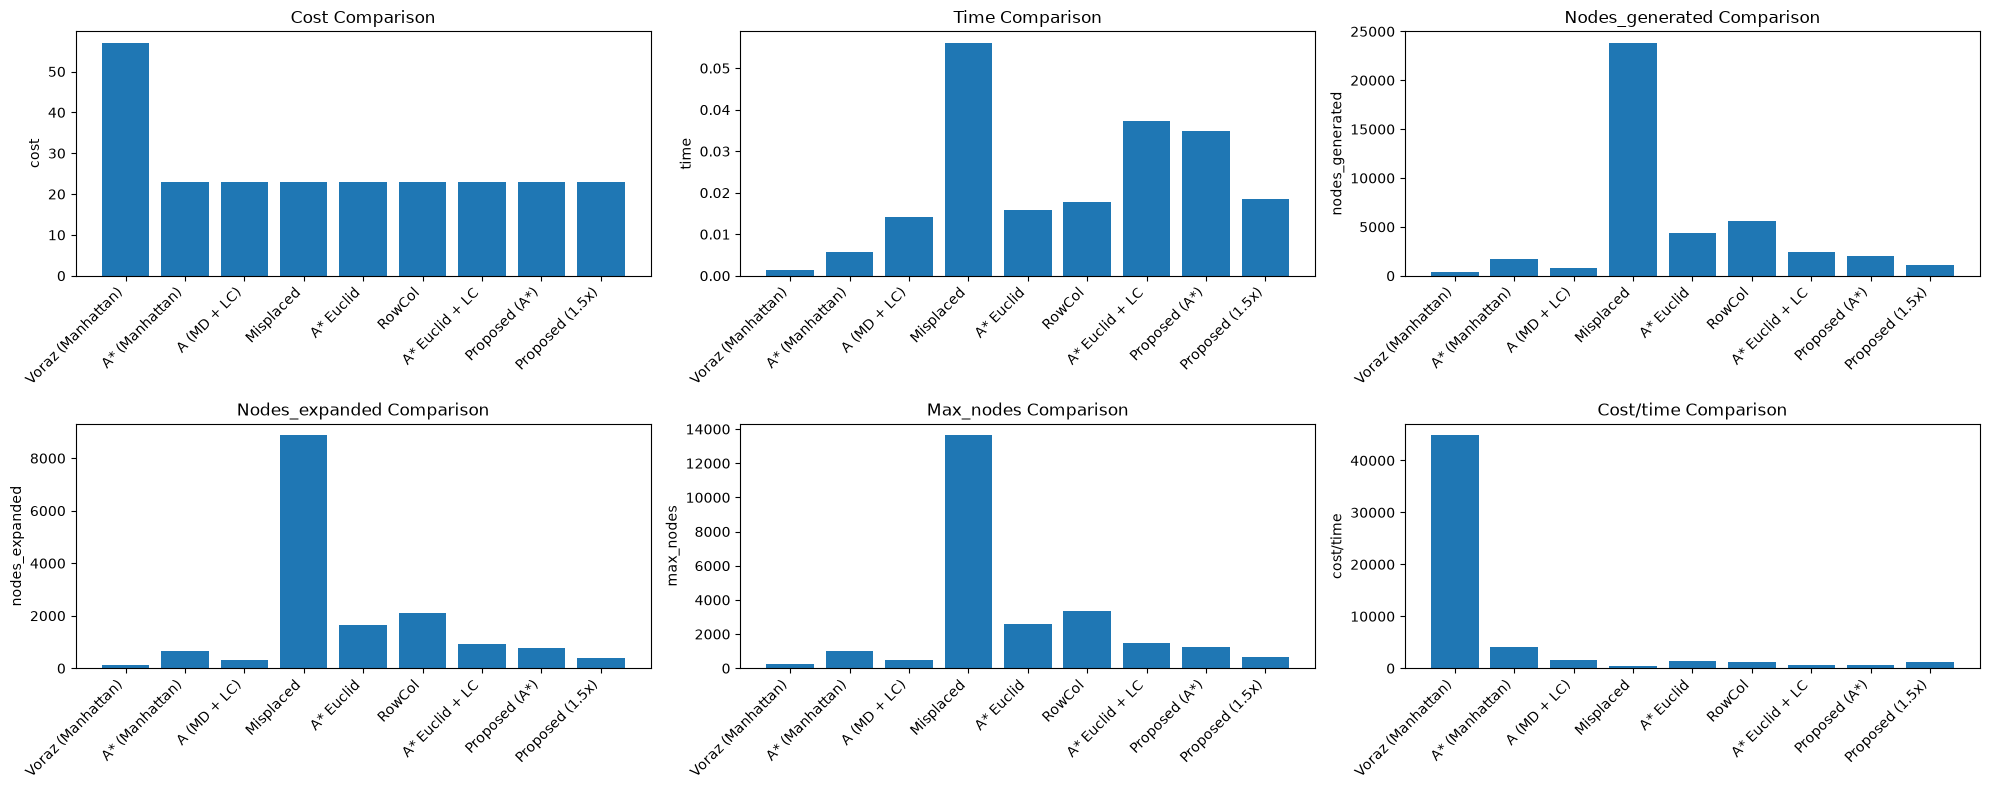

In [28]:
# Try with size n, auto-generating initial and goal states
size = 3
random.seed(5)
end_state = generate_ordered_state(size)
#end_state = generate_spiral_state(size)
initial_state = generate_random_state(size, end_state)

print("Initial state:\n")
visualize_state(initial_state)

print("\nEnd state:\n")
visualize_state(end_state)

print()
results = {}
for alg in ['Voraz (Manhattan)', 'A* (Manhattan)', 'A (MD + LC)', 'Misplaced', 'A* Euclid',
            'RowCol', 'A* Euclid + LC', 'Proposed (A*)', 'Proposed (1.5x)']:
    results.update(run_algorithm(alg, initial_state, end_state, size))

show_results(results)
plot_algorithm_comparison(results)

## Activity 6 – summary

| Heuristic | h(goal)=0, h≥0 | Admissible | Consistent | Search | Evidence (outputs above) |
|---|---|---|---|---|---|
| 2·Manhattan (example) | yes | **no** (32 > 22) | **no** | A | overestimation + counterexample in the first state |
| Misplaced | yes | yes | yes | A\* | 6/6 h ≤ h\*; complete check of the 181440 states |
| A\* Euclid (⌊E⌋) | yes | yes | yes | A\* | 6/6 h ≤ h\*; complete check of the 181440 states |
| RowCol | yes | yes | yes | A\* | 6/6 h ≤ h\*; complete check of the 181440 states |
| A\* Euclid + LC | yes | yes | **no** | A\* (with re-opening) | 6/6 h ≤ h\*; counterexample 15 → 13 |
| Proposed (A\*) = max(⌊E⌋, RC) + LC | yes | yes | **no** | A\* (with re-opening) | 6/6 h ≤ h\*; counterexample 15 → 13 |
| Proposed (1.5x) = 1.5·(max(⌊E⌋, RC) + LC) | yes | **no** (35/200 overestimations, e.g. 25.5 > 22) | **no** | A (weighted A\*, cost ≤ 1.5·opt) | counterexample 19.5 → 18.0 |

Note: the absence of counterexamples is empirical evidence. For the 3×3 puzzle with this goal, the consistency checks are exhaustive (all 181440 states), and the theoretical arguments in each reply extend them to any board size.